# Price Prediction

In [1]:
%pip install -q catboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split, ParameterSampler, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, PolynomialFeatures, TargetEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Load Data

<div dir="rtl">

متن آگهی‌ها (`title` و `description`) لازم نیست، چون ستون‌های `mentions_X` از قبل از متن ساخته شده‌اند.

</div>

In [3]:
df = pd.read_parquet('divar_clean.parquet')
df = df.drop(columns=['title', 'description'])
df.shape

(997409, 86)

## Data Selection

<div dir="rtl">

- فقط آگهی‌های فروش و اجاره. متغیر هدف `unified_price` است.
- آگهی‌های `is_wanted_ad` و `is_partial_offer` حذف می‌شوند، چون قیمتشان قیمت کل ملک نیست.
- آگهی‌های بدون متراژ حذف می‌شوند، چون بعداً قیمت هر متر لازم داریم.
- فقط بازه‌ی اصلی (`in_main_window`) می‌ماند، چون ماه آگهی یکی از featureهاست و ماه‌های بیرون از این بازه خیلی کم‌اند.

</div>

In [4]:
keep = (df['deal_type'].isin(['sale', 'rent'])
        & df['unified_price'].notna()
        & df['building_size'].notna()
        & ~df['is_wanted_ad']
        & ~df['is_partial_offer']
        & df['in_main_window'])
df = df[keep].copy()
df.shape

(857009, 86)

In [5]:
df['deal_type'].value_counts()

,count
deal_type,
sale,527284
rent,329725


## Features

<div dir="rtl">

- ستون‌های قیمت و هر چیزی که از قیمت ساخته شده وارد X نمی‌شوند.
- ستون‌های boolean به ۰ و ۱ تبدیل می‌شوند و missing همان missing می‌ماند.
- ماه آگهی به عدد تبدیل می‌شود تا اثر تورم را بگیرد.
- ستون‌های متنی فرم (نوع سند، نوع اجاره، گرمایش، سرمایش و ...) فقط در مدل‌های درختی استفاده می‌شوند، چون این مدل‌ها ستون categorical را مستقیم می‌پذیرند.

</div>

In [6]:
numeric_cols = ['building_size', 'land_size', 'rooms_count', 'construction_year', 'floor',
                'total_floors_count', 'unit_per_floor', 'location_latitude', 'location_longitude']
bool_cols = ['has_elevator', 'has_parking', 'has_warehouse', 'is_rebuilt', 'is_metro',
             'has_balcony_combined', 'has_security_guard_combined', 'has_pool_combined',
             'has_sauna_combined', 'has_jacuzzi_combined', 'has_barbecue_combined',
             'has_business_deed', 'rent_credit_transform', 'transformable_price']
keyword_cols = [c for c in df.columns if c.startswith('mentions_')]
cat_cols = ['cat3_slug', 'city_slug', 'neighborhood_slug']
form_cols = ['deed_type', 'rent_type', 'floor_material', 'has_heating_system', 'has_cooling_system',
             'has_warm_water_provider', 'building_direction', 'user_type']

In [7]:
X = df[numeric_cols + bool_cols + keyword_cols + cat_cols + form_cols + ['deal_type']].copy()
X[bool_cols + keyword_cols] = X[bool_cols + keyword_cols].astype(float)
X['month'] = df['created_at_month'].dt.month - 4  # 1 = May 2024
y = df['unified_price']
X.shape

(857009, 48)

In [8]:
X.isna().mean().sort_values(ascending=False).head(10).round(3)

,0
has_business_deed,0.971
has_barbecue_combined,0.967
has_sauna_combined,0.964
has_jacuzzi_combined,0.961
has_pool_combined,0.950
has_security_guard_combined,0.909
rent_type,0.884
land_size,0.806
deed_type,0.724
user_type,0.698


## Train / Validation / Test Split

<div dir="rtl">

داده به نسبت ۸۰، ۱۰ و ۱۰ درصد تقسیم می‌شود و نسبت فروش و اجاره در هر سه بخش یکسان می‌ماند. حدهای outlier، hyperparameterها و انتخاب مدل فقط با train و validation تعیین می‌شوند و test فقط یک بار در آخر استفاده می‌شود.

</div>

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, stratify=X['deal_type'], random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=X_temp['deal_type'], random_state=42)
len(X_train), len(X_val), len(X_test)

(685607, 85701, 85701)

In [10]:
pd.DataFrame({'train': X_train['deal_type'].value_counts(),
              'val': X_val['deal_type'].value_counts(),
              'test': X_test['deal_type'].value_counts()})

,train,val,test
deal_type,,,
sale,421827,52729,52728
rent,263780,32972,32973


## Target Skewness

In [11]:
(y_train / 1e6).groupby(X_train['deal_type']).agg(['min', 'median', 'max'])

,min,median,max
deal_type,,,
rent,1.0,500.0,4.666667e+07
sale,0.5,3000.0,8.000086e+07


In [12]:
pd.DataFrame({'price': y_train.groupby(X_train['deal_type']).skew(),
              'log(price)': np.log(y_train).groupby(X_train['deal_type']).skew()}).round(2)

,price,log(price)
deal_type,,
rent,511.32,0.52
sale,385.60,0.15


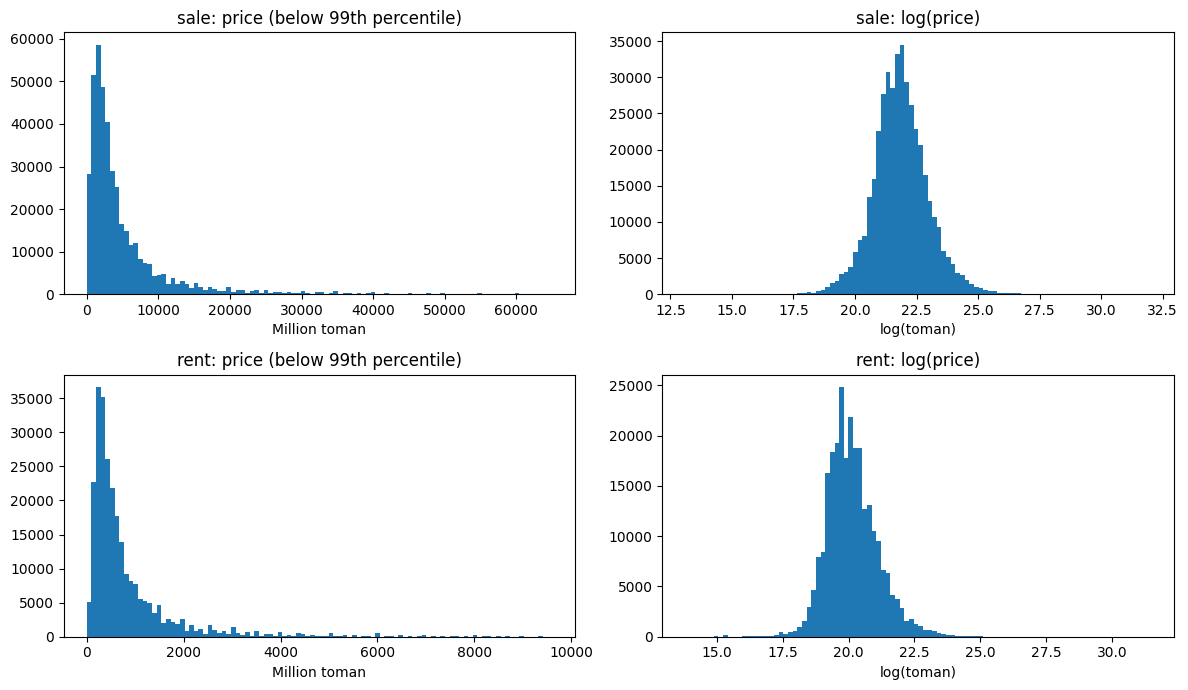

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, deal in enumerate(['sale', 'rent']):
    prices = y_train[X_train['deal_type'] == deal]
    below_p99 = prices[prices < prices.quantile(0.99)]
    axes[row, 0].hist(below_p99 / 1e6, bins=100)
    axes[row, 0].set_title(f'{deal}: price (below 99th percentile)')
    axes[row, 0].set_xlabel('Million toman')
    axes[row, 1].hist(np.log(prices), bins=100)
    axes[row, 1].set_title(f'{deal}: log(price)')
    axes[row, 1].set_xlabel('log(toman)')
plt.tight_layout()
plt.show()

<div dir="rtl">

قیمت‌ها حدود ۸ مرتبه‌ی بزرگی پخش شده‌اند و توزیعشان به‌شدت چوله به راست است. بعد از log، چولگی برای فروش به ۰.۱۵ و برای اجاره به ۰.۵۲ می‌رسد، پس مدل‌ها روی log قیمت آموزش می‌بینند. همه‌ی قیمت‌ها مثبت‌اند، پس `np.log` کافی است.

</div>

In [14]:
y_train_log = np.log(y_train)
y_val_log = np.log(y_val)
y_test_log = np.log(y_test)

## Outliers

<div dir="rtl">

- معیار outlier، log قیمت هر متر است، چون هم خطای قیمت را نشان می‌دهد هم خطای متراژ.
- حدهای IQR برای هر ترکیب `cat3_slug` و `is_metro` جدا و فقط از train حساب می‌شوند.
- outlierها فقط از train مدل‌های خطی حذف می‌شوند و validation و test دست نمی‌خورند.

</div>

In [15]:
def iqr_outliers(values, groups):
    q1 = values.groupby(groups).transform('quantile', 0.25)
    q3 = values.groupby(groups).transform('quantile', 0.75)
    iqr = q3 - q1
    return (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)

In [16]:
price_per_m2 = y_train / X_train['building_size']
groups = [X_train['cat3_slug'], X_train['is_metro']]
pd.Series({'price per m2': iqr_outliers(price_per_m2, groups).mean(),
           'log(price per m2)': iqr_outliers(np.log(price_per_m2), groups).mean()}).round(3)

,0
price per m2,0.062
log(price per m2),0.022


In [17]:
(price_per_m2.groupby(groups).median() / 1e6).unstack().round(1)

is_metro,0.0,1.0
cat3_slug,,
apartment-rent,4.3,8.2
apartment-sell,27.8,51.4
house-villa-rent,2.9,3.9
house-villa-sell,21.4,28.4
industry-agriculture-business-rent,2.0,2.8
industry-agriculture-business-sell,1.4,5.5
office-rent,6.4,14.3
office-sell,50.3,116.7
plot-old,4.3,6.6


In [18]:
log_price_per_m2 = np.log(price_per_m2)
outlier = iqr_outliers(log_price_per_m2, groups)

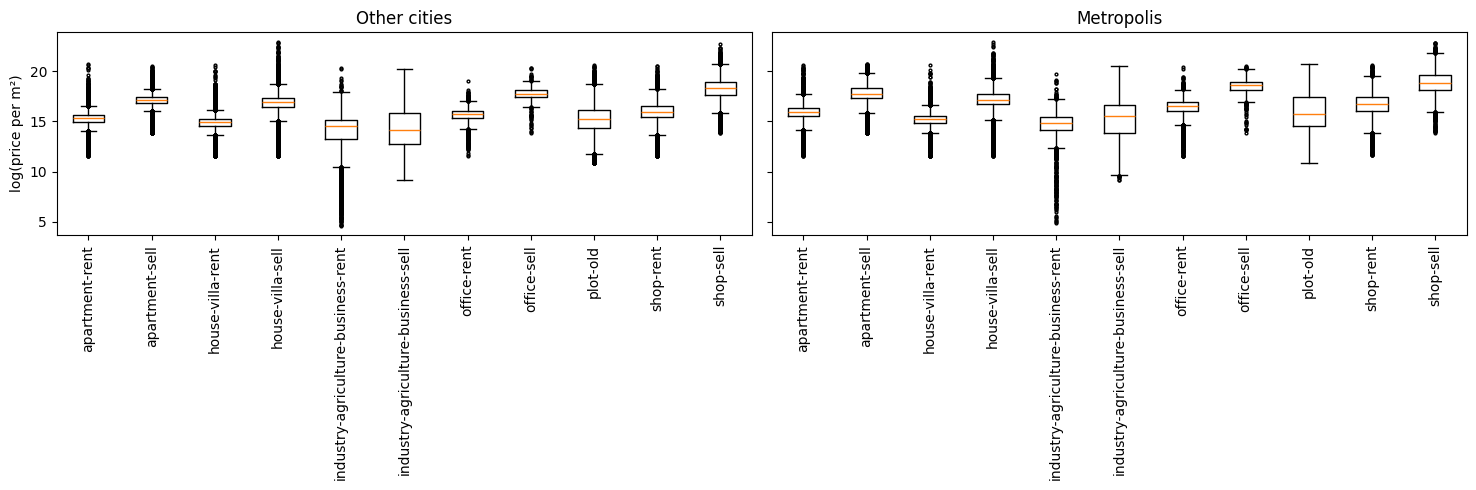

In [19]:
cats = sorted(X_train['cat3_slug'].unique())
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, metro in zip(axes, [0, 1]):
    in_group = X_train['is_metro'] == metro
    ax.boxplot([log_price_per_m2[in_group & (X_train['cat3_slug'] == c)] for c in cats], flierprops={'markersize': 2})
    ax.set_xticks(range(1, len(cats) + 1), cats, rotation=90)
    ax.set_title('Metropolis' if metro else 'Other cities')
axes[0].set_ylabel('log(price per m²)')
plt.tight_layout()
plt.show()

In [20]:
X_train_clean = X_train[~outlier]
y_train_clean_log = y_train_log[~outlier]
X_train_clean.shape

(670311, 48)

In [21]:
X_train_clean['deal_type'].value_counts()

,count
deal_type,
sale,412897
rent,257414


## General Model (Baseline)

<div dir="rtl">

- یک مدل `LinearRegression` برای فروش و اجاره با هم. نوع معامله از `cat3_slug` معلوم است (مثلاً `apartment-sell` و `apartment-rent`).
- متراژ با log وارد مدل می‌شود، چون هدف هم log قیمت است.
- missing در ستون‌های عددی با median و در ستون‌های boolean با صفر پر می‌شود. شهرها و محله‌هایی که کمتر از ۰.۱ درصد آگهی‌ها را دارند، در یک دسته‌ی مشترک قرار می‌گیرند.

</div>

In [22]:
def linear_model():
    features = ColumnTransformer([
        ('size', FunctionTransformer(np.log, feature_names_out='one-to-one'), ['building_size']),
        ('num', SimpleImputer(strategy='median'), ['rooms_count', 'construction_year', 'floor', 'month']),
        ('flag', SimpleImputer(strategy='constant', fill_value=0, keep_empty_feature=True), bool_cols + keyword_cols),
        ('cat', OneHotEncoder(min_frequency=0.001, handle_unknown='infrequent_if_exist'), cat_cols)])
    return make_pipeline(features, LinearRegression())

In [23]:
def evaluate(y_true_log, y_pred_log):
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)
    return {'R2 (log)': r2_score(y_true_log, y_pred_log),
            'R2': r2_score(y_true, y_pred),
            'MAE (M toman)': mean_absolute_error(y_true, y_pred) / 1e6,
            'MSE (M toman²)': mean_squared_error(y_true / 1e6, y_pred / 1e6)}

In [24]:
general = linear_model().fit(X_train_clean, y_train_clean_log)
results = {}
for deal in ['sale', 'rent']:
    in_val = X_val['deal_type'] == deal
    results[deal] = evaluate(y_val_log[in_val], general.predict(X_val[in_val]))
pd.DataFrame(results).T.round(3)

,R2 (log),R2,MAE (M toman),MSE (M toman²)
sale,0.549,0.212,3554.157,4.431839e+08
rent,0.683,0.175,459.738,1.149772e+07


In [25]:
def top10_share(prices):
    squares = (prices - prices.mean()) ** 2
    return squares.nlargest(10).sum() / squares.sum()

y_val.groupby(X_val['deal_type']).apply(top10_share).round(2)

,unified_price
deal_type,
rent,0.65
sale,0.41


<div dir="rtl">

در validation، ده آگهیِ گران‌ترین ۴۱ درصد مجموع مربعات فروش و ۶۵ درصد اجاره را می‌سازند. پس R² و MSE تومانی را عملاً همین چند آگهی تعیین می‌کنند، و برای مقایسه‌ی مدل‌ها از R² روی log استفاده می‌شود.

</div>

### General vs Separate

<div dir="rtl">

همین مدل یک بار هم جداگانه برای فروش و اجاره آموزش داده می‌شود.

</div>

In [26]:
models = {'general': general}
for deal in ['sale', 'rent']:
    in_train = X_train_clean['deal_type'] == deal
    models[deal] = linear_model().fit(X_train_clean[in_train], y_train_clean_log[in_train])

results = {}
for deal in ['sale', 'rent']:
    in_val = X_val['deal_type'] == deal
    results[(deal, 'general')] = evaluate(y_val_log[in_val], general.predict(X_val[in_val]))
    results[(deal, 'separate')] = evaluate(y_val_log[in_val], models[deal].predict(X_val[in_val]))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale general      0.549  0.212       3554.157    4.431839e+08
     separate     0.555  0.205       3560.964    4.469460e+08
rent general      0.683  0.175        459.738    1.149772e+07
     separate     0.686 -2.589        534.567    4.998795e+07

In [27]:
coefs = {}
for name, model in models.items():
    feature_names = model[0].get_feature_names_out()
    coefs[name] = pd.Series(model[-1].coef_, index=feature_names)
coefs = pd.DataFrame(coefs)
coefs.loc[['size__building_size', 'num__rooms_count', 'flag__has_parking', 'flag__has_elevator',
           'flag__mentions_new_building', 'flag__mentions_agency']].round(3)

,general,sale,rent
size__building_size,0.558,0.497,0.721
num__rooms_count,0.193,0.254,0.086
flag__has_parking,0.202,0.259,0.151
flag__has_elevator,0.182,0.203,0.177
flag__mentions_new_building,0.090,0.097,0.069
flag__mentions_agency,0.140,0.154,0.111


<div dir="rtl">

- دقت مدل کلی و مدل‌های جدا روی log تقریباً یکی است، چون مدل کلی هم نوع معامله را از `cat3_slug` می‌فهمد.
- ولی ضرایب خیلی فرق دارند. مثلاً دو برابر شدن متراژ، قیمت فروش را حدود ۴۱ درصد و اجاره را حدود ۶۵ درصد بالا می‌برد، و مدل کلی برای هر دو ۴۷ درصد می‌دهد.
- برای همین از اینجا فروش و اجاره جدا مدل می‌شوند.

</div>

## Separate Models

<div dir="rtl">

از اینجا فروش و اجاره جدا مدل می‌شوند.

</div>

### Encoding, Product and Power Features

<div dir="rtl">

- شهر و محله با `TargetEncoder` به میانگین log قیمت تبدیل می‌شوند. cross-fitting داخلی آن جلوی نشت قیمت هر آگهی را می‌گیرد.
- `PolynomialFeatures` با درجه‌ی ۲، توان دوم و ضرب دوبه‌دوی متراژ، ستون‌های عددی و `cat3_slug` را می‌سازد.

</div>

In [28]:
X_train[['city_slug', 'neighborhood_slug']].nunique()

,0
city_slug,419
neighborhood_slug,1174


In [29]:
def linear_features(degree):
    numeric = make_pipeline(
        ColumnTransformer([
            ('size', FunctionTransformer(np.log, feature_names_out='one-to-one'), ['building_size']),
            ('num', SimpleImputer(strategy='median'), ['rooms_count', 'construction_year', 'floor', 'month']),
            ('cat3', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['cat3_slug'])],
            verbose_feature_names_out=False),
        PolynomialFeatures(degree=degree, include_bias=False))
    return ColumnTransformer([
        ('numeric', numeric, ['building_size', 'rooms_count', 'construction_year', 'floor', 'month', 'cat3_slug']),
        ('flag', SimpleImputer(strategy='constant', fill_value=0, keep_empty_feature=True), bool_cols + keyword_cols),
        ('location', TargetEncoder(target_type='continuous', random_state=42), ['city_slug', 'neighborhood_slug'])],
        verbose_feature_names_out=False)

In [30]:
results = {}
linear_models = {}
for deal in ['sale', 'rent']:
    tr = X_train_clean['deal_type'] == deal
    va = X_val['deal_type'] == deal
    candidates = {'one-hot': linear_model(),
                  'target encoding': make_pipeline(linear_features(degree=1), LinearRegression()),
                  'target encoding + poly': make_pipeline(linear_features(degree=2), LinearRegression())}
    for name, model in candidates.items():
        model.fit(X_train_clean[tr], y_train_clean_log[tr])
        results[(deal, name)] = evaluate(y_val_log[va], model.predict(X_val[va]))
        linear_models[(deal, name)] = model
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale one-hot                    0.555  0.205       3560.964    4.469460e+08
     target encoding            0.579  0.226       3406.540    4.352753e+08
     target encoding + poly     0.595  0.106       3377.317    5.025276e+08
rent one-hot                    0.686 -2.589        534.567    4.998795e+07
     target encoding            0.697 -1.379        498.667    3.313279e+07
     target encoding + poly     0.716 -0.234        420.269    1.718120e+07

In [31]:
names = linear_models[('sale', 'target encoding + poly')][0].get_feature_names_out()
[n for n in names if 'building_size' in n][:12]

['building_size',
 'building_size^2',
 'building_size rooms_count',
 'building_size construction_year',
 'building_size floor',
 'building_size month',
 'building_size cat3_slug_apartment-sell',
 'building_size cat3_slug_house-villa-sell',
 'building_size cat3_slug_industry-agriculture-business-sell',
 'building_size cat3_slug_office-sell',
 'building_size cat3_slug_plot-old',
 'building_size cat3_slug_shop-sell']

<div dir="rtl">

- target encoding با ستون‌های خیلی کمتر از one-hot نتیجه‌ی بهتری می‌دهد.
- featureهای ضرب و توان R² روی log و MAE را برای هر دو گروه بهتر می‌کنند.
- R² تومانی همچنان به چند آگهی خیلی گران وابسته است.

</div>

### Dimension Reduction (PCA)

<div dir="rtl">

- ستون‌های poly به هم وابسته‌اند، مثلاً هر ستون با توان دومش. PCA آن‌ها را به مؤلفه‌های ناهمبسته تبدیل می‌کند. قبل از PCA همه‌ی ستون‌ها standardize می‌شوند.
- تعداد مؤلفه‌ها با R² روی validation انتخاب می‌شود.

</div>

In [32]:
explained = {}
pca_r2 = {}
for deal in ['sale', 'rent']:
    tr = X_train_clean['deal_type'] == deal
    va = X_val['deal_type'] == deal
    features = make_pipeline(linear_features(degree=2), StandardScaler())
    Z_train = features.fit_transform(X_train_clean[tr], y_train_clean_log[tr])
    Z_val = features.transform(X_val[va])

    pca = PCA().fit(Z_train)
    P_train, P_val = pca.transform(Z_train), pca.transform(Z_val)
    explained[deal] = np.cumsum(pca.explained_variance_ratio_)

    pca_r2[deal] = {}
    for k in [5, 10, 20, 30, 40, 50, 60, 80]:
        model = LinearRegression().fit(P_train[:, :k], y_train_clean_log[tr])
        pca_r2[deal][k] = r2_score(y_val_log[va], model.predict(P_val[:, :k]))

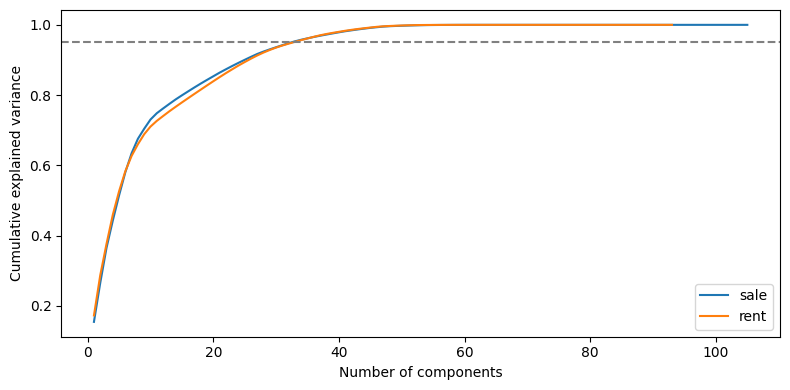

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
for deal, curve in explained.items():
    ax.plot(range(1, len(curve) + 1), curve, label=deal)
ax.axhline(0.95, color='grey', linestyle='--')
ax.set_xlabel('Number of components')
ax.set_ylabel('Cumulative explained variance')
ax.legend()
plt.tight_layout()
plt.show()

In [34]:
pd.DataFrame(pca_r2).round(3)

,sale,rent
5,0.164,0.298
10,0.425,0.620
20,0.528,0.641
30,0.535,0.649
40,0.575,0.684
50,0.585,0.702
60,0.592,0.715
80,0.595,0.716


<div dir="rtl">

- ۹۵ درصد واریانس با حدود ۳۰ مؤلفه حفظ می‌شود، ولی R² با این تعداد خیلی پایین‌تر است.
- با ۶۰ مؤلفه R² به مقدار کل featureها می‌رسد، پس مدل خطی نهایی PCA با ۶۰ مؤلفه دارد.

</div>

In [35]:
linear_final = {}
results = {}
for deal in ['sale', 'rent']:
    tr = X_train_clean['deal_type'] == deal
    va = X_val['deal_type'] == deal
    model = make_pipeline(linear_features(degree=2), StandardScaler(),
                          PCA(n_components=60, random_state=42), LinearRegression())
    model.fit(X_train_clean[tr], y_train_clean_log[tr])
    results[deal] = evaluate(y_val_log[va], model.predict(X_val[va]))
    linear_final[deal] = model
pd.DataFrame(results).T.round(3)

,R2 (log),R2,MAE (M toman),MSE (M toman²)
sale,0.592,0.087,3408.273,5.135911e+08
rent,0.715,-0.441,428.804,2.007605e+07


## Tree Models

<div dir="rtl">

- LightGBM و CatBoost ستون‌های categorical را خودشان مدیریت می‌کنند، پس شهر، محله، دسته‌ی ملک و ستون‌های متنی فرم مستقیم وارد می‌شوند. missing در این ستون‌ها یک دسته‌ی جدا می‌شود.
- تعداد درخت‌ها با early stopping روی validation تعیین می‌شود.

</div>

### Neighbor Price

<div dir="rtl">

- برای هر آگهی، میانگین log قیمت هر متر ۱۰ آگهی نزدیک از همان دسته در train با `KNeighborsRegressor` حساب می‌شود.
- برای ردیف‌های train این عدد out-of-fold ساخته می‌شود تا قیمت خود آگهی در آن نباشد.

</div>

In [36]:
coords = ['location_latitude', 'location_longitude']
for data in [X_train, X_val, X_test]:
    data['neighbor_price'] = np.nan

for cat in X_train['cat3_slug'].unique():
    fit = (X_train['cat3_slug'] == cat) & X_train['location_latitude'].notna()
    fit_coords = np.radians(X_train.loc[fit, coords])
    target = y_train_log[fit] - np.log(X_train.loc[fit, 'building_size'])
    knn = KNeighborsRegressor(n_neighbors=10, metric='haversine')
    X_train.loc[fit, 'neighbor_price'] = cross_val_predict(knn, fit_coords, target, cv=5)
    knn.fit(fit_coords, target)
    for data in [X_val, X_test]:
        query = (data['cat3_slug'] == cat) & data['location_latitude'].notna()
        data.loc[query, 'neighbor_price'] = knn.predict(np.radians(data.loc[query, coords]))
X_train['neighbor_price'].notna().groupby(X_train['deal_type']).mean().round(3)

,neighbor_price
deal_type,
rent,0.662
sale,0.644


In [37]:
tree_features = [c for c in X_train.columns if c != 'deal_type']
tree_cat_cols = cat_cols + form_cols

def tree_data(X):
    X = X[tree_features].copy()
    X[tree_cat_cols] = X[tree_cat_cols].fillna('missing').astype('category')
    return X

### Outliers and Tree Models

<div dir="rtl">

اثر حذف outlier روی LightGBM با تنظیم پیش‌فرض سنجیده می‌شود.

</div>

In [38]:
results = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    va = X_val['deal_type'] == deal
    for name, rows in [('outliers removed', tr & ~outlier), ('all train', tr)]:
        model = LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
        model.fit(tree_data(X_train[rows]), y_train_log[rows],
                  eval_set=[(tree_data(X_val[va]), y_val_log[va])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        results[(deal, name)] = evaluate(y_val_log[va], model.predict(tree_data(X_val[va])))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale outliers removed     0.723  0.214       2564.582    4.416970e+08
     all train            0.731  0.494       2444.567    2.846132e+08
rent outliers removed     0.769  0.371        332.968    8.762486e+06
     all train            0.785  0.395        310.683    8.426712e+06

<div dir="rtl">

- برای LightGBM حذف outlier ضرر دارد. با کل train، R² روی log برای فروش از ۰.۷۲۳ به ۰.۷۳۱ و برای اجاره از ۰.۷۶۹ به ۰.۷۸۵ می‌رسد و R² تومانی فروش از ۰.۲۱ به ۰.۴۹.
- پس مدل‌های درختی روی کل train آموزش می‌بینند.

</div>

## Hyperparameter Search

<div dir="rtl">

- برای هر مدل چند ترکیب تصادفی از hyperparameterها امتحان می‌شود (`ParameterSampler`) و ترکیبی که بیشترین R² روی log را در validation دارد انتخاب می‌شود.
- search روی یک زیرنمونه‌ی ۱۰۰ هزارتایی از train انجام می‌شود تا زمانش معقول بماند. بعد مدل با بهترین ترکیب روی کل train آموزش می‌بیند.
- در CatBoost ستون‌هایی که کمتر از ۱۰ مقدار دارند one-hot می‌شوند (`one_hot_max_size=10`) تا آموزش سریع‌تر شود.

</div>

In [39]:
lgbm_space = {'num_leaves': [31, 63, 127, 255],
              'learning_rate': [0.03, 0.05, 0.1],
              'min_child_samples': [10, 20, 50, 100],
              'colsample_bytree': [0.6, 0.8, 1.0],
              'reg_lambda': [0, 1, 10]}
catboost_space = {'depth': [6, 8],
                  'learning_rate': [0.2, 0.3],
                  'l2_leaf_reg': [1, 3, 10]}

In [40]:
search_rows = {}
for deal in ['sale', 'rent']:
    in_deal = X_train[X_train['deal_type'] == deal]
    search_rows[deal] = in_deal.sample(100_000, random_state=42).index

In [41]:
lgbm_search = []
best_lgbm_params = {}
for deal in ['sale', 'rent']:
    rows = search_rows[deal]
    va = X_val['deal_type'] == deal
    X_tr, y_tr = tree_data(X_train.loc[rows]), y_train_log[rows]
    X_va, y_va = tree_data(X_val[va]), y_val_log[va]
    best_score = -np.inf
    for params in ParameterSampler(lgbm_space, n_iter=12, random_state=42):
        model = LGBMRegressor(n_estimators=3000, random_state=42, verbose=-1, **params)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
        score = r2_score(y_va, model.predict(X_va))
        lgbm_search.append({'deal': deal, **params, 'trees': model.best_iteration_, 'R2 (log)': score})
        if score > best_score:
            best_score = score
            best_lgbm_params[deal] = params
lgbm_search = pd.DataFrame(lgbm_search)
lgbm_search.sort_values('R2 (log)', ascending=False).groupby('deal').head(3).round(4)

,deal,reg_lambda,num_leaves,min_child_samples,learning_rate,colsample_bytree,trees,R2 (log)
15,rent,0,127,50,0.03,0.6,331,0.7837
23,rent,1,255,20,0.05,0.6,153,0.7835
13,rent,0,63,50,0.05,0.6,332,0.7821
11,sale,1,255,20,0.05,0.6,248,0.7166
7,sale,1,255,10,0.03,0.8,342,0.7161
10,sale,0,255,10,0.03,0.8,412,0.7159


In [42]:
best_lgbm_params

{'sale': {'reg_lambda': 1,
  'num_leaves': 255,
  'min_child_samples': 20,
  'learning_rate': 0.05,
  'colsample_bytree': 0.6},
 'rent': {'reg_lambda': 0,
  'num_leaves': 127,
  'min_child_samples': 50,
  'learning_rate': 0.03,
  'colsample_bytree': 0.6}}

In [43]:
lgbm_tuned = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    va = X_val['deal_type'] == deal
    model = LGBMRegressor(n_estimators=5000, random_state=42, verbose=-1, **best_lgbm_params[deal])
    model.fit(tree_data(X_train[tr]), y_train_log[tr],
              eval_set=[(tree_data(X_val[va]), y_val_log[va])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    lgbm_tuned[deal] = model
{deal: m.best_iteration_ for deal, m in lgbm_tuned.items()}

{'sale': 412, 'rent': 538}

In [44]:
catboost_search = []
best_catboost_params = {}
for deal in ['sale', 'rent']:
    rows = search_rows[deal]
    va = X_val['deal_type'] == deal
    X_tr, y_tr = tree_data(X_train.loc[rows]), y_train_log[rows]
    X_va, y_va = tree_data(X_val[va]), y_val_log[va]
    best_score = -np.inf
    for params in ParameterSampler(catboost_space, n_iter=5, random_state=42):
        model = CatBoostRegressor(iterations=3000, cat_features=tree_cat_cols, one_hot_max_size=10,
                                  early_stopping_rounds=100, random_seed=42, verbose=0, **params)
        model.fit(X_tr, y_tr, eval_set=(X_va, y_va))
        score = r2_score(y_va, model.predict(X_va))
        catboost_search.append({'deal': deal, **params, 'trees': model.best_iteration_, 'R2 (log)': score})
        if score > best_score:
            best_score = score
            best_catboost_params[deal] = params
catboost_search = pd.DataFrame(catboost_search)
catboost_search.sort_values('R2 (log)', ascending=False).groupby('deal').head(3).round(4)

,deal,learning_rate,l2_leaf_reg,depth,trees,R2 (log)
7,rent,0.2,1,6,697,0.7777
5,rent,0.2,10,8,333,0.7773
9,rent,0.3,10,6,561,0.7768
2,sale,0.2,1,6,1214,0.7084
3,sale,0.2,3,8,686,0.7083
0,sale,0.2,10,8,699,0.7080


In [45]:
best_catboost_params

{'sale': {'learning_rate': 0.2, 'l2_leaf_reg': 1, 'depth': 6},
 'rent': {'learning_rate': 0.2, 'l2_leaf_reg': 1, 'depth': 6}}

In [46]:
catboost_tuned = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    va = X_val['deal_type'] == deal
    model = CatBoostRegressor(iterations=5000, cat_features=tree_cat_cols, one_hot_max_size=10,
                              early_stopping_rounds=100, random_seed=42, verbose=0, **best_catboost_params[deal])
    model.fit(tree_data(X_train[tr]), y_train_log[tr], eval_set=(tree_data(X_val[va]), y_val_log[va]))
    catboost_tuned[deal] = model
{deal: m.best_iteration_ for deal, m in catboost_tuned.items()}

{'sale': 3248, 'rent': 646}

### Validation Comparison

<div dir="rtl">

پیش‌بینی نهایی میانگین پیش‌بینی LightGBM و CatBoost است.

</div>

In [47]:
def blend_predict(deal, X):
    Z = tree_data(X)
    return (lgbm_tuned[deal].predict(Z) + catboost_tuned[deal].predict(Z)) / 2

In [48]:
results = {}
for deal in ['sale', 'rent']:
    va = X_val['deal_type'] == deal
    results[(deal, 'linear (poly + PCA)')] = evaluate(y_val_log[va], linear_final[deal].predict(X_val[va]))
    results[(deal, 'LightGBM')] = evaluate(y_val_log[va], lgbm_tuned[deal].predict(tree_data(X_val[va])))
    results[(deal, 'CatBoost')] = evaluate(y_val_log[va], catboost_tuned[deal].predict(tree_data(X_val[va])))
    results[(deal, 'LightGBM + CatBoost')] = evaluate(y_val_log[va], blend_predict(deal, X_val[va]))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale linear (poly + PCA)     0.592  0.087       3408.273    5.135911e+08
     LightGBM                0.737  0.467       2416.486    2.994336e+08
     CatBoost                0.729  0.399       2565.340    3.380774e+08
     LightGBM + CatBoost     0.739  0.449       2432.338    3.096774e+08
rent linear (poly + PCA)     0.715 -0.441        428.804    2.007605e+07
     LightGBM                0.789  0.413        305.543    8.175164e+06
     CatBoost                0.785  0.500        312.761    6.962471e+06
     LightGBM + CatBoost     0.791  0.455        303.768    7.595832e+06

<div dir="rtl">

- مدل‌های درختی خیلی بهتر از مدل خطی‌اند.
- میانگین LightGBM و CatBoost در هر دو گروه بیشترین R² روی log را دارد و مدل نهایی است.

</div>

## Final Evaluation on Test

<div dir="rtl">

مدل‌ها فقط یک بار روی test سنجیده می‌شوند.

</div>

In [49]:
results = {}
for deal in ['sale', 'rent']:
    te = X_test['deal_type'] == deal
    results[(deal, 'baseline (general linear)')] = evaluate(y_test_log[te], general.predict(X_test[te]))
    results[(deal, 'linear (poly + PCA)')] = evaluate(y_test_log[te], linear_final[deal].predict(X_test[te]))
    results[(deal, 'LightGBM + CatBoost')] = evaluate(y_test_log[te], blend_predict(deal, X_test[te]))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale baseline (general linear)     0.549  0.218       3600.810    4.690345e+08
     linear (poly + PCA)           0.590 -0.486       3472.787    8.915810e+08
     LightGBM + CatBoost           0.734  0.469       2471.834    3.186867e+08
rent baseline (general linear)     0.685  0.071        479.834    4.035219e+07
     linear (poly + PCA)           0.715 -0.042        445.848    4.526510e+07
     LightGBM + CatBoost           0.798  0.205        322.737    3.454584e+07

### Effect of Extreme Ads

<div dir="rtl">

همان حدهای IQR که از train به دست آمد روی test اعمال می‌شود تا معلوم شود معیارها چقدر به آگهی‌های بیرون از این حدها وابسته‌اند. این فقط برای تحلیل است و مدل تغییری نمی‌کند.

</div>

In [50]:
fences = log_price_per_m2.groupby(groups).quantile([0.25, 0.75]).unstack()
fences.columns = ['q1', 'q3']
fences['low'] = fences['q1'] - 1.5 * (fences['q3'] - fences['q1'])
fences['high'] = fences['q3'] + 1.5 * (fences['q3'] - fences['q1'])

test_fences = X_test[['cat3_slug', 'is_metro']].join(fences[['low', 'high']], on=['cat3_slug', 'is_metro'])
test_log_price_per_m2 = np.log(y_test / X_test['building_size'])
inside = test_log_price_per_m2.between(test_fences['low'], test_fences['high'])
inside.groupby(X_test['deal_type']).mean().round(3)

,0
deal_type,
rent,0.976
sale,0.980


In [51]:
results = {}
for deal in ['sale', 'rent']:
    te = X_test['deal_type'] == deal
    results[(deal, 'all test ads')] = evaluate(y_test_log[te], blend_predict(deal, X_test[te]))
    results[(deal, 'inside IQR fences')] = evaluate(y_test_log[te & inside], blend_predict(deal, X_test[te & inside]))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale all test ads          0.734  0.469       2471.834    3.186867e+08
     inside IQR fences     0.758  0.506       2183.034    2.476032e+08
rent all test ads          0.798  0.205        322.737    3.454584e+07
     inside IQR fences     0.858  0.699        240.047    1.852319e+06

### Error by Category

<div dir="rtl">

خطای نسبی هر آگهی برابر قدر مطلق نسبت پیش‌بینی به قیمت واقعی منهای یک است.

</div>

In [52]:
errors = []
for deal in ['sale', 'rent']:
    te = X_test['deal_type'] == deal
    predicted = np.exp(blend_predict(deal, X_test[te]))
    errors.append(pd.DataFrame({'cat3_slug': X_test.loc[te, 'cat3_slug'],
                                'error': abs(predicted / y_test[te] - 1)}))
errors = pd.concat(errors)
errors.groupby('cat3_slug')['error'].agg(['count', 'median']).round(3)

,count,median
cat3_slug,,
apartment-rent,20189,0.120
apartment-sell,28743,0.115
house-villa-rent,6009,0.200
house-villa-sell,10828,0.270
industry-agriculture-business-rent,730,0.424
industry-agriculture-business-sell,742,0.610
office-rent,1888,0.205
office-sell,393,0.229
plot-old,10347,0.502


### Predicted vs Actual

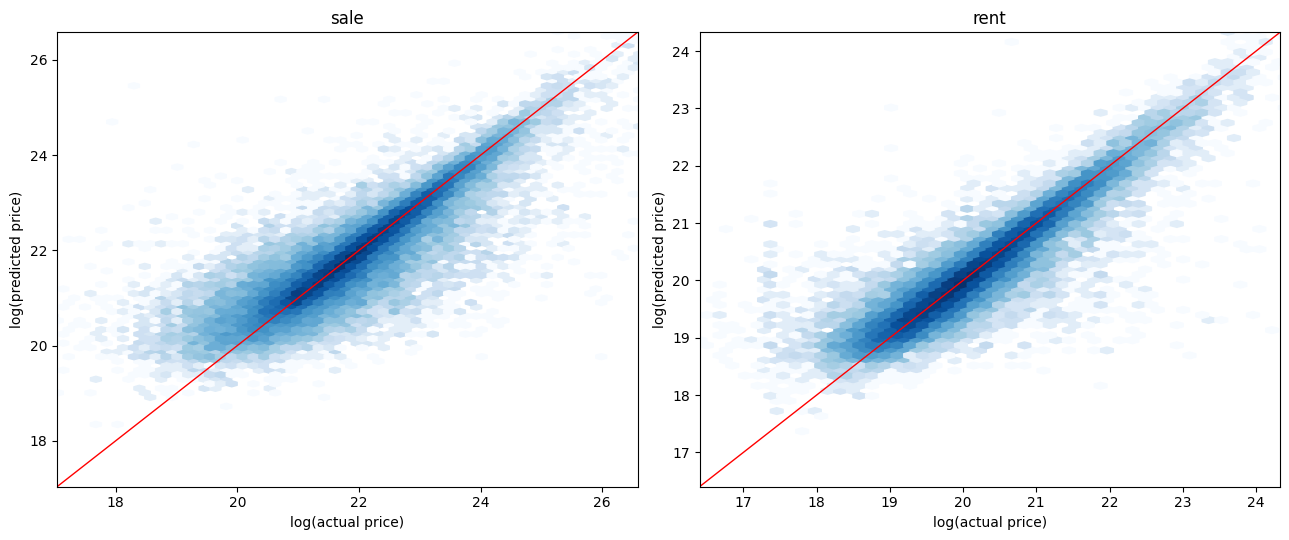

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, deal in zip(axes, ['sale', 'rent']):
    te = X_test['deal_type'] == deal
    predicted = blend_predict(deal, X_test[te])
    ax.hexbin(y_test_log[te], predicted, gridsize=80, bins='log', cmap='Blues')
    low, high = y_test_log[te].quantile([0.001, 0.999])
    ax.plot([low, high], [low, high], color='red', linewidth=1)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_title(deal)
    ax.set_xlabel('log(actual price)')
    ax.set_ylabel('log(predicted price)')
plt.tight_layout()
plt.show()

### Feature Importance (LightGBM)

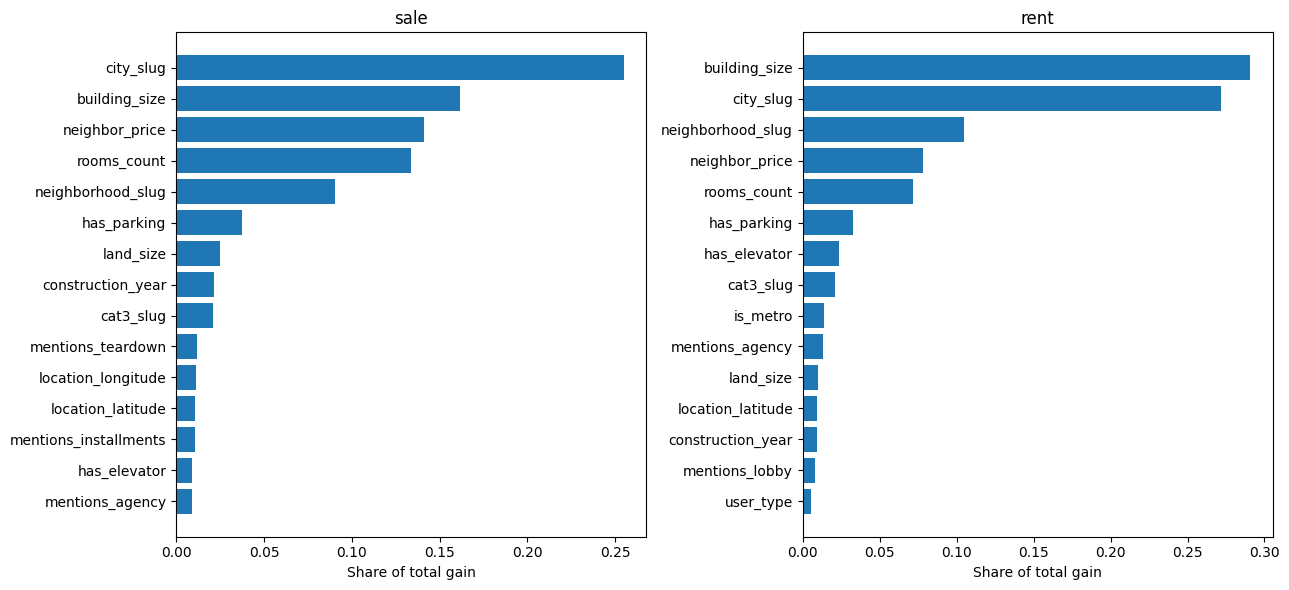

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, deal in zip(axes, ['sale', 'rent']):
    booster = lgbm_tuned[deal].booster_
    importance = pd.Series(booster.feature_importance('gain'), index=booster.feature_name())
    importance = (importance / importance.sum()).sort_values().tail(15)
    ax.barh(importance.index, importance.values)
    ax.set_title(deal)
    ax.set_xlabel('Share of total gain')
plt.tight_layout()
plt.show()

## Conclusion

<div dir="rtl">

- مدل نهایی روی test، R² روی log را برای فروش از ۰.۵۵ (baseline) به ۰.۷۳ و برای اجاره از ۰.۶۹ به ۰.۸۰ می‌رساند و MAE را حدود ۳۰ درصد کم می‌کند.
- R² تومانی فروش ۰.۴۷ و اجاره ۰.۲۱ است. این عدد به حدود ۲ درصد آگهی‌هایی وابسته است که بیرون حدهای IQR هستند؛ روی بقیه‌ی آگهی‌ها R² تومانی فروش ۰.۵۱ و اجاره ۰.۷۰ است.
- خطای نسبی معمول برای آپارتمان حدود ۱۲ درصد است. زمین، ملک صنعتی و کشاورزی و مغازه خطای خیلی بیشتری دارند (۴۰ تا ۶۰ درصد).
- مهم‌ترین featureها شهر، متراژ، محله و قیمت همسایه‌ها هستند. تعداد اتاق در فروش مهم‌تر از اجاره است.

</div>

## Bonus: Text Feature

<div dir="rtl">

- این بخش از پردازش متن استفاده می‌کند و خارج از سرفصل اصلی است.
- پیش‌بینی یک `Ridge` روی TF-IDF عنوان و توضیح آگهی به‌عنوان feature به LightGBM داده می‌شود (برای train به‌صورت out-of-fold). عددها و کلمه‌های مبلغ قبل از آن از متن حذف می‌شوند.

</div>

In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

In [56]:
text = pd.read_parquet('divar_clean.parquet', columns=['title', 'description'])
text = (text['title'].fillna('') + ' ' + text['description'].fillna('')).loc[X_train.index.append([X_val.index, X_test.index])]
money_words = 'تومان|تومن|میلیون|ملیون|میلیارد|ملیارد|هزار|قیمت|رهن|اجاره|ودیعه|پول|نقد|مبلغ|فی|متری|توافقی|قسط|اقساط|وام'
text = text.str.replace(r'[0-9۰-۹٠-٩]+', ' ', regex=True).str.replace(money_words, ' ', regex=True)

In [57]:
text_price = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    other = X_val.index[X_val['deal_type'] == deal].append(X_test.index[X_test['deal_type'] == deal])
    vectorizer = TfidfVectorizer(max_features=30000, min_df=5, sublinear_tf=True)
    T_train = vectorizer.fit_transform(text.loc[X_train.index[tr]])
    ridge = Ridge(alpha=3.0)
    train_part = pd.Series(cross_val_predict(ridge, T_train, y_train_log[tr], cv=5), index=X_train.index[tr])
    ridge.fit(T_train, y_train_log[tr])
    other_part = pd.Series(ridge.predict(vectorizer.transform(text.loc[other])), index=other)
    text_price[deal] = pd.concat([train_part, other_part])

In [58]:
lgbm_text = {}
results = {}
for deal in ['sale', 'rent']:
    tr = X_train['deal_type'] == deal
    va = X_val['deal_type'] == deal
    te = X_test['deal_type'] == deal
    Z_train = tree_data(X_train[tr]).assign(text_price=text_price[deal])
    Z_val = tree_data(X_val[va]).assign(text_price=text_price[deal])
    Z_test = tree_data(X_test[te]).assign(text_price=text_price[deal])
    model = LGBMRegressor(n_estimators=5000, random_state=42, verbose=-1, **best_lgbm_params[deal])
    model.fit(Z_train, y_train_log[tr], eval_set=[(Z_val, y_val_log[va])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    lgbm_text[deal] = model
    results[(deal, 'val')] = evaluate(y_val_log[va], model.predict(Z_val))
    results[(deal, 'test')] = evaluate(y_test_log[te], model.predict(Z_test))
pd.DataFrame(results).T.round(3)

R2 (log)     R2  MAE (M toman)  MSE (M toman²)
sale val      0.792  0.529       2196.022    2.647280e+08
     test     0.788  0.518       2260.899    2.889478e+08
rent val      0.814  0.419        292.407    8.097264e+06
     test     0.816  0.201        306.335    3.470417e+07

<div dir="rtl">

- نسبت به مدل نهایی بخش اصلی، feature متنی برای فروش بیشترین اثر را دارد: روی test، R² روی log از ۰.۷۳ به ۰.۷۹، R² تومانی از ۰.۴۷ به ۰.۵۲ و MAE از ۲,۴۷۲ به ۲,۲۶۱ میلیون تومان می‌رسد.
- برای اجاره، R² روی log از ۰.۸۰ به ۰.۸۲ و MAE از ۳۲۳ به ۳۰۶ میلیون تومان می‌رسد و R² تومانی تقریباً ثابت می‌ماند.

</div>